<a href="https://colab.research.google.com/github/AbhinandLaji/Ai-Ml-lab/blob/main/ucs_and_A_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Least cost path from A to D: A -> D with total cost 3


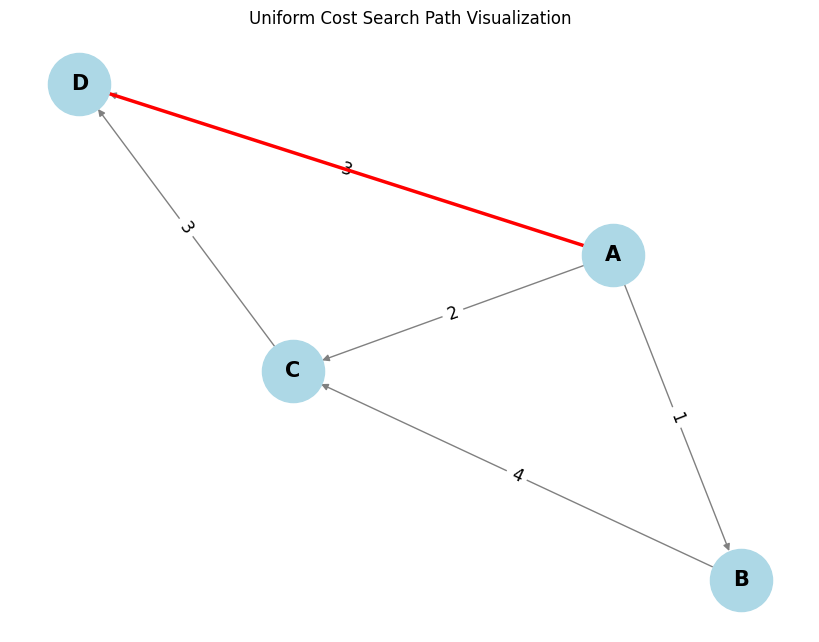

In [ ]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

def uniform_cost_search(graph, start, goal):
    priority_queue = [(0, start)]
    visited = {start: (0, None)}

    while priority_queue:
        current_cost, current_node = heapq.heappop(priority_queue)

        if current_node == goal:
            return current_cost, reconstruct_path(visited, start, goal)

        for neighbour, cost in graph[current_node]:
            total_cost = current_cost + cost
            if neighbour not in visited or total_cost < visited[neighbour][0]:
                visited[neighbour] = (total_cost, current_node)
                heapq.heappush(priority_queue, (total_cost, neighbour))
    return None

def reconstruct_path(visited, start, goal):
    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = visited[current][1]
    path.reverse()
    return path

def visualize_graph(graph, path=None):
    G = nx.DiGraph()
    for node, edges in graph.items():
        for neighbours, cost in edges:
            G.add_edge(node, neighbours, weight=cost)

    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=2000, font_size=15, font_weight='bold', edge_color='gray')
    labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=12)

    if path:
        path_edges = list(zip(path, path[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=2.5)
        plt.title("Uniform Cost Search Path Visualization")

    plt.show()

if __name__ == "__main__":

    graph = {
        'A': [('B', 1), ('C', 2), ('D', 3)],
        'B': [('C', 4)],
        'C': [('D', 3)],
        'D': []
    }

    start_node = 'A'
    goal_node = 'D'
    result = uniform_cost_search(graph, start_node, goal_node)

    if result:
        total_cost, path = result
        print(f"Least cost path from {start_node} to {goal_node}: {' -> '.join(path)} with total cost {total_cost}")
        visualize_graph(graph, path)
    else:
        print(f"No path found from {start_node} to {goal_node}")

Least cost path from A to D: A -> B -> C -> D with total cost 4


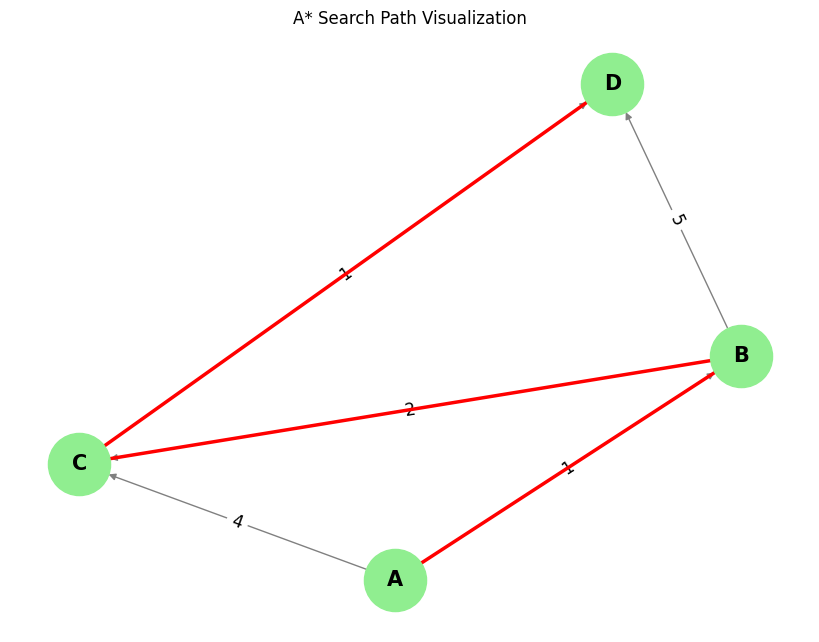

In [ ]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

def a_star_search(graph, start, goal, heuristic):
    priority_queue = [(heuristic[start], 0, start)]
    visited = {start: (0, None)}

    while priority_queue:
        _, current_cost, current_node = heapq.heappop(priority_queue)

        if current_node == goal:
            return current_cost, reconstruct_path(visited, start, goal)

        for neighbour, cost in graph[current_node]:
            total_cost = current_cost + cost

            if neighbour not in visited or total_cost < visited[neighbour][0]:
                visited[neighbour] = (total_cost, current_node)
                f_cost = total_cost + heuristic[neighbour]
                heapq.heappush(priority_queue, (f_cost, total_cost, neighbour))

    return None

def reconstruct_path(visited, start, goal):
    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = visited[current][1]
    path.reverse()
    return path

def visualize_graph(graph, path=None):
    G = nx.DiGraph()
    for node, edges in graph.items():
        for neighbours, cost in edges:
            G.add_edge(node, neighbours, weight=cost)

    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_color='lightgreen', node_size=2000, font_size=15, font_weight='bold', edge_color='gray')
    labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=12)

    if path:
        path_edges = list(zip(path, path[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=2.5)
        plt.title("A* Search Path Visualization")

    plt.show()

if __name__ == "__main__":
    graph = {
        'A': [('B', 1), ('C', 4)],
        'B': [('C', 2), ('D', 5)],
        'C': [('D', 1)],
        'D': []
    }

    heuristic = {
        'A': 4,
        'B': 2,
        'C': 1,
        'D': 0
    }

    start_node = 'A'
    goal_node = 'D'
    result = a_star_search(graph, start_node, goal_node, heuristic)

    if result:
        total_cost, path = result
        print(f"Least cost path from {start_node} to {goal_node}: {' -> '.join(path)} with total cost {total_cost}")
        visualize_graph(graph, path)
    else:
        print(f"No path found from {start_node} to {goal_node}")